# File 6: New-Tenancy Rent Gap (Auckland)

*File and column names keep the word "premium" (`rent_premium_pct`) so downstream code keeps working; the measure is an observed gap.*

## Purpose
Two free sources measure rent in different ways:
- **MBIE bonds:** the rent agreed on **new** tenancies, which is the market price today.
- **2023 Census:** the rent **every** renting household was paying on census night (7 March 2023), including tenants who have
  stayed for years and social-housing tenants.

The difference between them is an **observed gap** (`rent_premium_pct` in the output) between two different rental
populations: new tenancies, and all renting households including long-stay and social-housing tenants. It is not a measure of
what any one tenancy or property earns. Three questions:
1. How large is the observed gap between new-tenancy rent and the rent all renting households pay?
2. How much of the gap is social housing? Kāinga Ora tenants pay income-related rent (about 25% of income), not market rent.
3. Where is the gap largest, and does a low turnover proxy (File 5) go with a bigger gap?

## Inputs
| File | What |
|---|---|
| `data/census/census_2013_2018_2023_households_sa2.csv` | 2023 census: median weekly rent paid, rent bands, sector of landlord |
| `data/clean/rent_timeseries_by_sa2.csv` | Quarterly bond median rent by SA2, with `rent_source_sa2` |
| `data/rental/mbie_quarterly_sa2_2020_2026.csv` | Raw MBIE file: new bonds lodged (`Total Bonds`) per source SA2, the sample-size test |
| `data/clean/auckland_rent_monthly.csv` | Official Auckland monthly bond series (File 5) |
| `master_flagged.csv`, `area_profiles_by_sa2.csv`, `rent_market_by_sa2.csv` | Flags (File 1), area types (File 3), turnover (File 5) |

## Steps
1. Load census rent and landlord sector
2. Auckland: what renters pay against what new tenants pay
3. The gap for each SA2, and its sensitivity to the sample cut-off
4. How much is social housing?
5. The gap where social housing is small
6. Does low turnover widen the gap?
7. Map
8. Save outputs

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load census rent and landlord sector

In [2]:
# STEP 1: CENSUS 2023 RENT AND LANDLORD SECTOR (-999 = suppressed by Stats NZ for confidentiality)
h = pd.read_csv('data/census/census_2013_2018_2023_households_sa2.csv').replace(-999, np.nan)
h = h.assign(sa2_code=h['SA22023_V1_00'].astype(int))
sector = {'VAR_4_163': 'private', 'VAR_4_164': 'council', 'VAR_4_165': 'kainga_ora', 'VAR_4_166': 'iwi',
          'VAR_4_167': 'community', 'VAR_4_168': 'govt_other', 'VAR_4_171': 'sector_stated'}
BANDS = {'VAR_4_250': (0, 200), 'VAR_4_251': (200, 300), 'VAR_4_252': (300, 400), 'VAR_4_253': (400, 500),
         'VAR_4_254': (500, 600), 'VAR_4_255': (600, 700), 'VAR_4_256': (700, 800), 'VAR_4_257': (800, None)}
c = h[['sa2_code'] + list(sector) + list(BANDS)].rename(columns=sector)
# social = income-related or below-market landlords: Kāinga Ora, council, community housing providers
c['social_pct'] = 100 * c[['kainga_ora', 'council', 'community']].sum(axis=1, min_count=1) / c.sector_stated
c['kainga_ora_pct'] = 100 * c.kainga_ora / c.sector_stated
c['private_landlord_pct'] = 100 * c.private / c.sector_stated

m = (pd.read_csv(CLEAN / 'master_flagged.csv')
       .merge(pd.read_csv(CLEAN / 'area_profiles_by_sa2.csv', usecols=['sa2_code', 'area_type']), on='sa2_code')
       .merge(c, on='sa2_code', how='left'))
assert len(m) == 633 and m.sa2_code.is_unique

tot = m[list(sector.values())].sum()
print(f'Auckland renting households stating a landlord: {tot.sector_stated:,.0f}')
print((100 * tot.drop('sector_stated') / tot.sector_stated).round(1).sort_values(ascending=False).to_string())

Auckland renting households stating a landlord: 206,496
private       82.9
kainga_ora    14.4
community      1.5
govt_other     0.6
council        0.5
iwi            0.1


**Reading this:** of 206,500 Auckland renting households that stated a landlord, **83% rent privately** and **14% from Kāinga Ora**.
Council and community housing providers add another 2%. Kāinga Ora tenants mostly pay income-related rent (capped near 25% of income).
That rent has nothing to do with the market, so wherever Kāinga Ora is a big landlord, the census median rent will sit far below
bond rent.

### Step 2: Auckland, what renters pay against what new tenants pay

Census 2023, all renting households: median $540/wk (Stats NZ published; band interpolation $545)
New bonds, average of the Oct 2022 - Mar 2023 monthly medians: $603/wk
Observed gap: +11.7% ($63/wk)


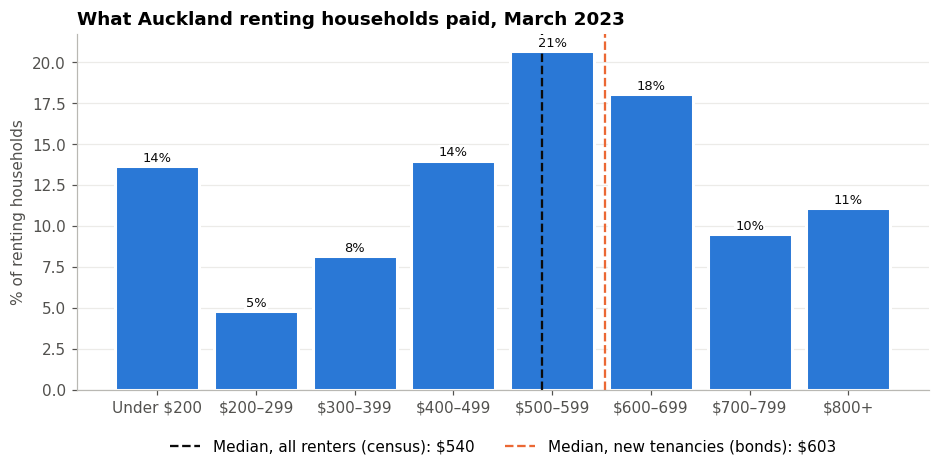

Paying under $300: 18% of renting households


In [3]:
# STEP 2: AUCKLAND-WIDE. Census: Stats NZ's published Auckland median weekly rent, 2023 Census (all renting households).
# Bonds: the average of the six official monthly medians of new bonds lodged, Oct 2022 - Mar 2023.
CENSUS_AKL_PUBLISHED = 540   # Stats NZ, 2023 Census population, dwelling and housing highlights
census_akl = CENSUS_AKL_PUBLISHED

# Check only: rebuild the median from the census rent bands by grouped-median interpolation (band holding the middle
# household, households assumed spread evenly across it). It should land close to the published figure.
counts = m[list(BANDS)].sum()
half, cum = counts.sum() / 2, counts.cumsum()
band = cum[cum >= half].index[0]
lo, hi = BANDS[band]
census_interp = lo + (half - (cum[band] - counts[band])) / counts[band] * (hi - lo)
assert abs(census_interp - census_akl) < 15

akl = pd.read_csv(CLEAN / 'auckland_rent_monthly.csv', parse_dates=['month'], index_col='month')
bond_akl = akl.loc['2022-10':'2023-03', 'median_rent'].mean()   # average of 6 monthly medians, not a 6-month median
print(f'Census 2023, all renting households: median ${census_akl:.0f}/wk (Stats NZ published; band interpolation ${census_interp:.0f})')
print(f'New bonds, average of the Oct 2022 - Mar 2023 monthly medians: ${bond_akl:.0f}/wk')
print(f'Observed gap: {100 * (bond_akl / census_akl - 1):+.1f}% (${bond_akl - census_akl:.0f}/wk)')

labels = ['Under $200', '$200–299', '$300–399', '$400–499', '$500–599', '$600–699', '$700–799', '$800+']
share = 100 * counts / counts.sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(range(8), share.values, color=BLUE, edgecolor='white', linewidth=2, width=0.85)
for x, v in enumerate(share.values):
    ax.annotate(f'{v:.0f}%', (x, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8.5, color=INK,
                bbox=dict(boxstyle='square,pad=0.1', fc='white', ec='none'), zorder=5)
xpos = lambda v: v / 100 - 1.5   # $ -> bar position: the $100-wide band starting at $100k sits at k-1 (valid for $200+)
for v, name, col in [(census_akl, 'all renters (census)', INK), (bond_akl, 'new tenancies (bonds)', ORANGE)]:
    ax.axvline(xpos(v), color=col, lw=1.5, ls='--', label=rf'Median, {name}: \${v:.0f}')
ax.set_xticks(range(8), [s.replace('$', r'\$') for s in labels]); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set(title='What Auckland renting households paid, March 2023', ylabel='% of renting households')
fig.savefig(VIZ / '06_census_rent_bands.png'); plt.show()
print(f'Paying under $300: {share.iloc[:2].sum():.0f}% of renting households')

**Reading this:**
- Stats NZ publishes the 2023 Census Auckland median as **\$540/wk** for all renting households (the band interpolation here
  gives \$545 and is kept only as a check). New tenancies in the six months to census averaged **\$603/wk** (the mean of six
  official monthly bond medians). That is an **observed gap of about 12% (\$63/wk)** between two different rental populations,
  not what any one tenancy is short of the market.
- The two medians sit in neighbouring bands (\$500–599 and \$600–699).
- The **14% paying under \$200** is mostly income-related social rent: no private Auckland market rent is that low.

*Check method:* **grouped-median interpolation.** The census gives counts in \$100 bands, so a median can be placed inside its
band by assuming households are spread evenly across it. It lands \$5 from the published figure, which is used instead.

### Step 3: The gap for each SA2

In [4]:
# STEP 3: SA2 GAP = bond median rent (Oct-Dec 2022 and Jan-Mar 2023) / census median rent paid - 1
# Sample size = NEW bonds lodged over those two quarters (MBIE 'Total Bonds'), from the raw quarterly file so a quarter
# with a suppressed median still counts its lodgements. Active bonds would let an SA2 pass with very few new tenancies.
CENSUS_Q = pd.to_datetime(['2022-10-01', '2023-01-01'])
ts = pd.read_csv(CLEAN / 'rent_timeseries_by_sa2.csv', parse_dates=['quarter'])
w = ts[ts.quarter.isin(CENSUS_Q)].groupby('sa2_code')
raw = pd.read_csv('data/rental/mbie_quarterly_sa2_2020_2026.csv', dtype=str,
                  usecols=['TimeFrame', 'Location Id', 'Dwelling Type', 'Number Of Beds', 'Total Bonds'])
raw = raw[(raw['Dwelling Type'] == 'ALL') & (raw['Number Of Beds'] == 'ALL')]
raw = raw[pd.to_datetime(raw.TimeFrame, dayfirst=True).isin(CENSUS_Q)]
lodged = (raw.assign(src=pd.to_numeric(raw['Location Id'], errors='coerce'), n=pd.to_numeric(raw['Total Bonds'], errors='coerce'))
             .groupby('src').n.sum(min_count=1).rename('lodged_census_time'))
m = (m.join(w.median_rent.mean().rename('bond_rent_census_time'), on='sa2_code')
      .join(w.median_rent.count().rename('rent_quarters_census_time'), on='sa2_code')   # quarters with a published median (1 or 2)
      .join(lodged, on='rent_source_sa2'))
m['rent_premium_pct'] = 100 * (m.bond_rent_census_time / m.census_median_rent_weekly - 1)
m['rent_premium_dollars'] = m.bond_rent_census_time - m.census_median_rent_weekly

# Keep SA2s where both sides describe the SAME place with enough new tenancies:
#   shared-rent SA2s carry their MBIE source SA2's bond figure but their own census figure -> not comparable
MIN_LODGED = 30
base_scope = m.analysis_ready & ~m.flag_borrowed_rent & m.rent_premium_pct.notna()
in_scope = base_scope & (m.lodged_census_time >= MIN_LODGED)
m['in_premium_analysis'] = in_scope
p = m[in_scope].copy()
print(f'SA2s compared: {len(p)} with {MIN_LODGED}+ new bonds lodged (left out: {m.analysis_ready.sum() - len(p)} analysis-ready SA2s '
      'with shared rent, no census median, or too few lodgements)')
print(f'Of those, {(p.rent_quarters_census_time == 1).sum()} have a published bond median in only one of the two quarters')

# Sensitivity to the cut-off
sens = []
for k in [20, 30, 50]:
    s = m[base_scope & (m.lodged_census_time >= k)]
    pv = s[s.social_pct < 5]
    sens.append({'min lodged': k, 'SA2s': len(s), 'median gap %': s.rent_premium_pct.median(),
                 'median gap $': s.rent_premium_dollars.median(), 'one-quarter rent': int((s.rent_quarters_census_time == 1).sum()),
                 'SA2s <5% social': len(pv), 'their median gap %': pv.rent_premium_pct.median()})
print(pd.DataFrame(sens).set_index('min lodged').round(1).to_string())
print(f'Observed gap: median {p.rent_premium_pct.median():+.0f}% (${p.rent_premium_dollars.median():.0f}/wk), '
      f'middle half {p.rent_premium_pct.quantile(.25):+.0f}% to {p.rent_premium_pct.quantile(.75):+.0f}%')
print(f'SA2s where new tenants pay LESS than existing renters: {(p.rent_premium_pct < 0).sum()}')
cols = ['sa2_name', 'area_type', 'bond_rent_census_time', 'census_median_rent_weekly', 'rent_premium_pct', 'social_pct']
pd.concat([p.nlargest(6, 'rent_premium_pct')[cols], p.nsmallest(6, 'rent_premium_pct')[cols]]).round(1)

SA2s compared: 305 with 30+ new bonds lodged (left out: 294 analysis-ready SA2s with shared rent, no census median, or too few lodgements)
Of those, 0 have a published bond median in only one of the two quarters
            SA2s  median gap %  median gap $  one-quarter rent  SA2s <5% social  their median gap %
min lodged                                                                                         
20           366          12.1          69.0                 0              158                 8.1
30           305          11.2          64.0                 0              129                 7.1
50           166           9.5          54.5                 0               67                 5.9
Observed gap: median +11% ($64/wk), middle half +6% to +18%
SA2s where new tenants pay LESS than existing renters: 28


,sa2_name,area_type,bond_rent_census_time,census_median_rent_weekly,rent_premium_pct,social_pct
474,Māngere West,Crowded family suburbs,622.5,200.0,211.2,72.8
509,Wesley West,Crowded family suburbs,626.5,230.0,172.4,65.2
203,Glen Innes East-Wai O Taiki Bay,Middle suburbs,635.0,280.0,126.8,51.3
249,Bayswater,Affluent established suburbs,655.0,300.0,118.3,35.9
278,Waterview,Middle suburbs,615.5,298.0,106.5,50.7
525,Ponsonby West,Affluent established suburbs,1091.5,545.0,100.3,29.0
542,Grafton,Apartments & inner city,280.0,520.0,-46.2,1.8
620,The Strand,Apartments & inner city,374.0,570.0,-34.4,0.0
142,Alfriston,Middle suburbs,427.5,630.0,-32.1,17.6
286,Unsworth Heights East,Middle suburbs,431.5,606.0,-28.8,7.4


**Reading this:**
- **305 SA2s** had 30 or more new bonds lodged over Oct 2022 – Mar 2023 (MBIE `Total Bonds`, `lodged_census_time`). Across them,
  new-tenancy rent was a median **11% (\$64/wk) above** census rent paid; for the middle half of SA2s, between 6% and 18%.
- **Why 294 analysis-ready SA2s are left out:** 141 share their bond rent with another SA2 (same MBIE source SA2) but have their own
  census rent; 24 have no census or bond median; 129 had fewer than 30 new lodgements.
- **The sample rule changed the result.** The previous version required 30 *active* bonds, so 128 SA2s passed with only 6–27 new
  lodgements behind their rent figure. They are now out. Grange enters (it had been wrongly flagged as sharing rent).
- **Sensitivity:** at 20 lodgements, 366 SA2s and a median gap of 12.1%; at 50, 166 SA2s and 9.5%. The gap narrows as the minimum
  sample rises, so thin samples push it up. Quote the gap with its cut-off.
- **Coverage:** every compared SA2 has a published bond median in both quarters (`rent_quarters_census_time` = 2).
- **Gaps over 100%** (7 SA2s) are mostly where most renters have a social landlord, such as Māngere West (73% social) and Wesley
  West (65%), where the census median is \$200–230. Step 4 deals with this.
- **28 SA2s show new tenants paying *less*.** The biggest are dwelling-mix effects, not falling rent:
  - Grafton and The Strand: new bonds are mostly student rooms and studios, while census households include whole apartments.
  - Alfriston and Unsworth Heights East: the bonds likely include room lets or smaller new units.

  Treat any SA2 gap below zero as a mix signal.

### Step 4: How much is social housing?

Spearman correlation, gap vs social share: 0.56
Line fitted on all 305 SA2s:            gap = 0.6% + 1.11 x social share  (misleading)
Line fitted on 263 SA2s under 30% social: gap = 5.7% + 0.47 x social share


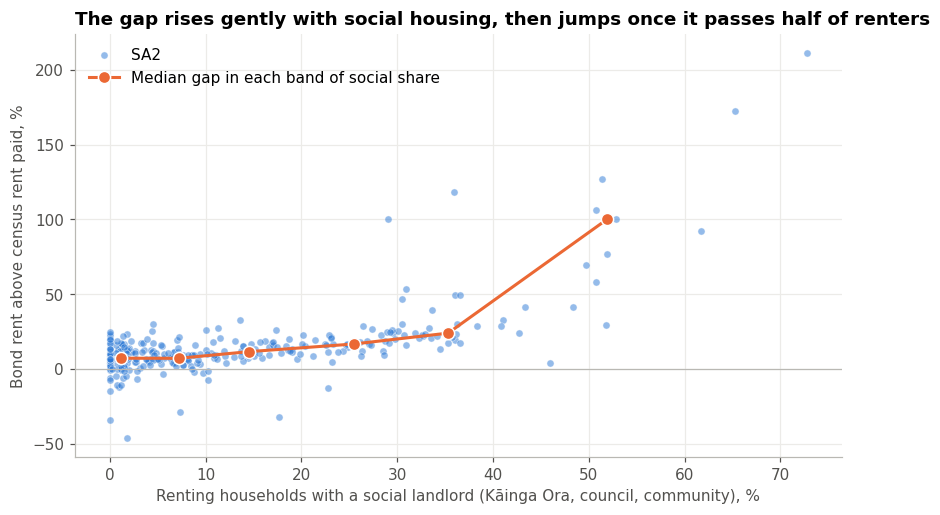

,mid,median,count
social share,,,
0–5%,1.2,7.1,129
5–10%,7.2,7.1,46
10–20%,14.6,11.6,50
20–30%,25.5,16.7,38
30–50%,35.3,23.9,33
50%+,51.9,100.2,9


In [5]:
# STEP 4: SOCIAL HOUSING. Kāinga Ora tenants pay income-related rent, so a high social share drags the census
# median far below market. First look at the median gap in bands of social share (no model assumed).
rho = p.rent_premium_pct.corr(p.social_pct, method='spearman')
edges, names = [-0.1, 5, 10, 20, 30, 50, 100], ['0–5%', '5–10%', '10–20%', '20–30%', '30–50%', '50%+']
bins = pd.cut(p.social_pct, edges, labels=names)
by_band = p.groupby(bins, observed=True).agg(mid=('social_pct', 'median'), median=('rent_premium_pct', 'median'), count=('sa2_code', 'size'))
print(f'Spearman correlation, gap vs social share: {rho:.2f}')

# The bands show the relationship is NOT a straight line: flat until about 30%, then steep. A line fitted to all SA2s
# would be dragged by the few 50%+ SA2s, so fit it only where it is roughly straight (under 30% social):
#   a (intercept) = gap with NO social housing;  b (slope) = extra gap per point of social share
low = p[p.social_pct < 30]
b, a = np.polyfit(low.social_pct, low.rent_premium_pct, 1)
b_all, a_all = np.polyfit(p.social_pct, p.rent_premium_pct, 1)
print(f'Line fitted on all {len(p)} SA2s:            gap = {a_all:.1f}% + {b_all:.2f} x social share  (misleading)')
print(f'Line fitted on {len(low)} SA2s under 30% social: gap = {a:.1f}% + {b:.2f} x social share')

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(p.social_pct, p.rent_premium_pct, s=22, color=BLUE, alpha=0.5, edgecolor='white', linewidth=0.5, label='SA2')
ax.plot(by_band['mid'], by_band['median'], color=ORANGE, lw=2, marker='o', markersize=8, markeredgecolor='white',
        label='Median gap in each band of social share')
ax.axhline(0, color=GREY, lw=0.8)
ax.legend(frameon=False, loc='upper left')
ax.set(title='The gap rises gently with social housing, then jumps once it passes half of renters',
       xlabel='Renting households with a social landlord (Kāinga Ora, council, community), %',
       ylabel='Bond rent above census rent paid, %')
fig.savefig(VIZ / '06_premium_vs_social.png'); plt.show()
by_band.round(1).rename_axis('social share')

**Reading this:**
- **Social housing explains the extremes, not the typical gap.** With under 30% social, the gap only creeps up, from about 7%
  to 17%. Above half, the census median *is* the income-related rent, and the gap passes 100%.
- **A lesson in fitting lines.** A straight line through all SA2s says "0.6% plus 1.11 points per point of social housing". That
  intercept is wrong: the few extreme SA2s tilt the whole line. Fitted only where the data is roughly straight (under 30% social),
  the intercept is **+5.7%**, close to the binned median of 7% in the lowest bands.
  *Always look at binned medians or the scatter before trusting a fitted line.*
- **Practical rule:** in SA2s with over 30% social housing, census rent is **not** a market signal. Don't use it for yields or
  affordability there.

### Step 5: The gap where social housing is small

(a) intercept: +5.7%   (b) median across 129 SA2s with under 5% social: +7.1% ($48/wk)
Left off the chart (fewer than 10 SA2s): Crowded family suburbs (n=1)


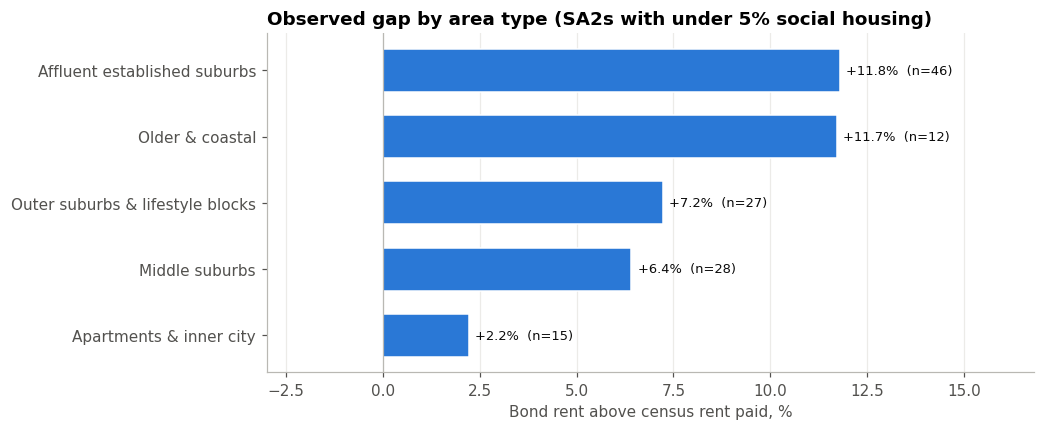

,median,count
area_type,,
Apartments & inner city,2.2,15
Middle suburbs,6.4,28
Outer suburbs & lifestyle blocks,7.2,27
Older & coastal,11.7,12
Affluent established suburbs,11.8,46


In [6]:
# STEP 5: GAP WITHOUT SOCIAL HOUSING. Two ways to take social housing out, which should roughly agree:
#   (a) the intercept of the line fitted under 30% social (Step 4)
#   (b) the median gap in SA2s where under 5% of renters have a social landlord
priv = p[p.social_pct < 5]
print(f'(a) intercept: {a:+.1f}%   (b) median across {len(priv)} SA2s with under 5% social: {priv.rent_premium_pct.median():+.1f}% '
      f'(${priv.rent_premium_dollars.median():.0f}/wk)')

bt = priv.groupby('area_type').rent_premium_pct.agg(['median', 'count'])
print('Left off the chart (fewer than 10 SA2s):', ', '.join(f'{t} (n={n})' for t, n in bt['count'][bt['count'] < 10].items()) or 'none')
bt = bt[bt['count'] >= 10].sort_values('median')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(bt.index, bt['median'], color=BLUE, edgecolor='white', linewidth=1, height=0.65)
for y, (v, n) in enumerate(zip(bt['median'], bt['count'])):
    ax.annotate(f'{v:+.1f}%  (n={n})', (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                ha='left' if v >= 0 else 'right', va='center', fontsize=8.5, color=INK)
ax.axvline(0, color=GREY, lw=0.8); ax.grid(axis='y', visible=False)
ax.set_xlim(min(0, bt['median'].min()) - 3, bt['median'].max() + 5)
ax.set(title='Observed gap by area type (SA2s with under 5% social housing)', xlabel='Bond rent above census rent paid, %')
fig.savefig(VIZ / '06_premium_by_type.png'); plt.show()
bt.round(1)

**Reading this:**
- **The two methods are close:** where social housing is small, the observed gap is **about 6–7%** (intercept +5.7%; median
  across 129 SA2s with under 5% social housing +7.1%, or \$48/wk). Before the lodgement rule this was 10–11%; most of the drop
  comes from removing SA2s with thin new-tenancy samples.
- It compares two populations (new tenancies and all renting households in mostly private areas). It does not say what any one
  tenanted property earns below market, so no investor figure is drawn from it.
- **By area type:**
  - The gap is largest in **affluent established suburbs and older & coastal areas (about 12%)**.
  - It is smallest in **apartments & inner city (2%)**, which also have the highest turnover proxy in File 5.
  - Crowded family suburbs have only 1 SA2 under 5% social housing, so they are left off.

### Step 6: Does low turnover widen the gap?

In [7]:
# STEP 6: TURNOVER. If tenants who stay longer get smaller rent rises, SA2s with LOW turnover (File 5) should show a
# BIGGER gap. Test on the low-social SA2s only, so social housing doesn't drive the result.
tv = pd.read_csv(CLEAN / 'rent_market_by_sa2.csv', usecols=['sa2_code', 'turnover_pct'])
priv = priv.merge(tv, on='sa2_code').dropna(subset=['turnover_pct'])
rho_t = priv.rent_premium_pct.corr(priv.turnover_pct, method='spearman')
q = pd.qcut(priv.turnover_pct, 3, labels=['Low turnover', 'Middle', 'High turnover'])
print(f'Private-market SA2s with turnover: {len(priv)} | Spearman gap vs turnover proxy: {rho_t:.2f}')
priv.groupby(q, observed=True).agg(turnover=('turnover_pct', 'median'), premium=('rent_premium_pct', 'median'),
                                   n=('sa2_code', 'size')).round(1)

Private-market SA2s with turnover: 128 | Spearman gap vs turnover proxy: -0.16


,turnover,premium,n
turnover_pct,,,
Low turnover,24.9,9.9,43
Middle,28.7,6.8,42
High turnover,34.2,6.8,43


**Reading this:**
- The direction is as expected: low-social SA2s with the lowest turnover proxy (File 5: bond closures ÷ active bonds) have the
  biggest gap (9.9%, against 6.8% for the middle and highest thirds). But the link is **weak** (Spearman −0.16).
- Turnover explains the gap between area *types* (apartments against established suburbs, Step 5) better than the gap between
  individual SA2s.
- Within similar suburbs, other things matter more: the age of the housing, how long the current tenants have stayed, and landlord
  type (many long-held properties are let below market to keep good tenants).

*Honest result:* the turnover idea from File 5 holds at the broad level and is weak at SA2 level. Report it that way.

### Step 7: Map

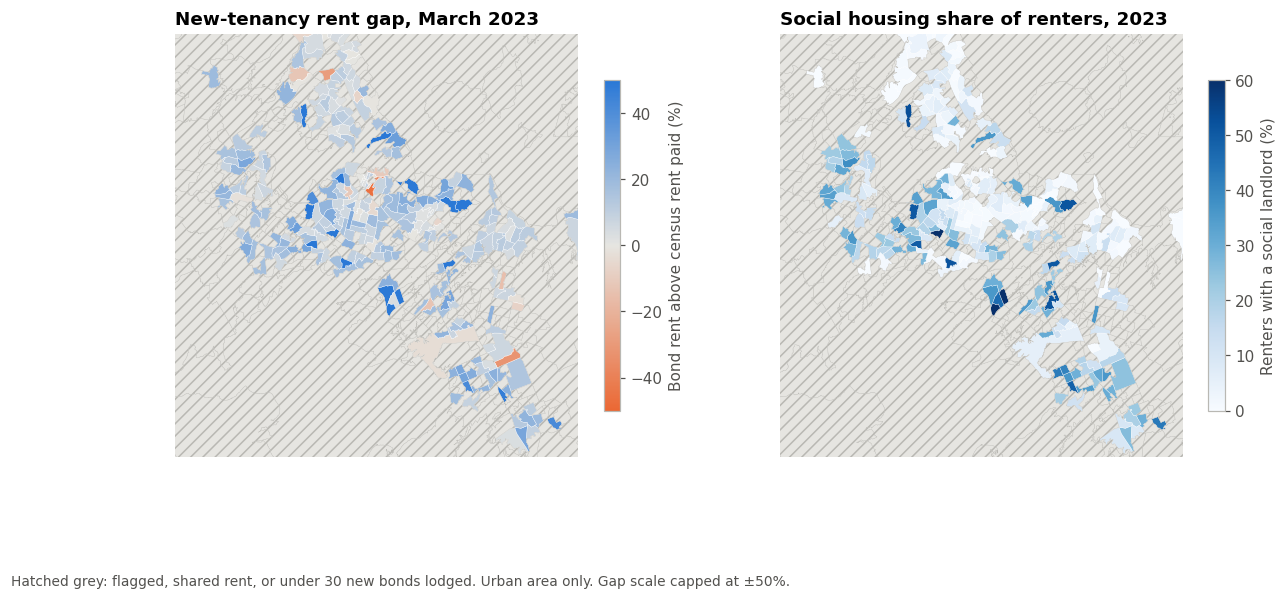

In [8]:
# STEP 7: MAPS, gap (diverging: below / above zero) and social share (sequential)
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson'); geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)
gm = geo[['sa2_code', 'geometry']].merge(m, on='sa2_code')
ok, bad = gm[gm.in_premium_analysis], gm[~gm.in_premium_analysis]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
ok.plot(column='rent_premium_pct', cmap=DIV, vmin=-50, vmax=50, ax=axes[0], edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Bond rent above census rent paid (%)', 'shrink': 0.6})
ok.plot(column='social_pct', cmap=SEQ, vmin=0, vmax=60, ax=axes[1], edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Renters with a social landlord (%)', 'shrink': 0.6})
for ax, t in zip(axes, ['New-tenancy rent gap, March 2023', 'Social housing share of renters, 2023']):
    bad.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.2)
    ax.set_title(t); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.02, 'Hatched grey: flagged, shared rent, or under 30 new bonds lodged. Urban area only. Gap scale capped at ±50%.',
         color=MUTED, fontsize=9)
fig.savefig(VIZ / '06_premium_maps.png'); plt.show()

### Step 8: Save outputs

In [9]:
# STEP 8: SAVE
out = CLEAN / 'rent_premium_by_sa2.csv'
keep = ['sa2_code', 'sa2_name', 'area_type', 'rent_source_sa2', 'bond_rent_census_time', 'rent_quarters_census_time',
        'lodged_census_time', 'census_median_rent_weekly', 'rent_premium_pct', 'rent_premium_dollars', 'social_pct',
        'kainga_ora_pct', 'private_landlord_pct', 'flag_borrowed_rent', 'analysis_ready', 'in_premium_analysis']
m[keep].round(2).to_csv(out, index=False)
chk = pd.read_csv(out)
assert len(chk) == 633 and chk.sa2_code.is_unique and chk.in_premium_analysis.sum() == len(p)
assert chk.social_pct.dropna().between(0, 100).all()
print(f'Saved {out} ({len(chk)} rows, {chk.in_premium_analysis.sum()} in the gap analysis)')
print('Charts:', ', '.join(sorted(f.name for f in VIZ.glob('06_*.png'))))

Saved data\clean\rent_premium_by_sa2.csv (633 rows, 305 in the gap analysis)
Charts: 06_census_rent_bands.png, 06_premium_by_type.png, 06_premium_maps.png, 06_premium_vs_social.png


# File 6: New-Tenancy Rent Gap - Summary

## Key findings
| Question | Answer |
|---|---|
| Who are Auckland's landlords? | 83% private, 14% Kāinga Ora, 2% council and community (2023 census) |
| Auckland: new tenancies against all renters | **\$603 (mean of six monthly bond medians, Oct 2022 – Mar 2023) against \$540 (Stats NZ, 2023 Census): an observed gap of about 12%** between two rental populations |
| Typical SA2 gap | +11% (\$64/wk); middle half +6% to +18%, across 305 SA2s with 30+ new bonds lodged |
| Sensitivity to the sample cut-off | 20 lodgements: 366 SA2s, +12.1%. 50 lodgements: 166 SA2s, +9.5% |
| Gap where social housing is small (under 5%) | **About 6–7%** (\$48/wk, 129 SA2s); intercept method +5.7% |
| Where is the gap largest? | Affluent established suburbs and older & coastal areas (about 12%); smallest in apartments (2%) |
| Does a low turnover proxy go with a bigger gap? | Weakly (Spearman −0.16) |
| Social-heavy SA2s | Over 50% social: census rent is income-related and the gap passes 100%. Not a market signal |

## What this changes
- **File 2 affordability:** its ratio uses *new-tenancy* rent against all-household income, an area-level measure. In social-heavy
  SA2s, households actually pay income-related rent, so it is not a measure of what renters pay.
- **Yields (Files 1 and 4):** gross yield uses new-tenancy rent, so it is a market-rent yield proxy. This file does not support a
  figure for how much less a tenanted property earns.
- **Dashboard:** show the gap only for SA2s in the analysis (30+ new lodgements, under 30% social), with the lodgement count, and
  flag the rest.

## Caveats
- Timing: the bond window (Oct 2022 – Mar 2023) centres about two months before census night. Rents rose about 1–2% in that gap,
  so the gap is slightly *understated*.
- Census rent is self-reported. Bonds include room lets; census rent is per household. Dwelling mix differs, as in Grafton.
- Sample: 30+ new bonds lodged over the two quarters; shared-rent SA2s left out (294 analysis-ready SA2s out in total).
- Two different populations: new tenancies against all renting households. The gap is observed, not a lag for any one tenancy.
- One census, one point in time: there's no way to see whether the gap is widening.

## Outputs
- `data/clean/rent_premium_by_sa2.csv`: one row per SA2: `rent_source_sa2`, bond rent at census time, quarters with a published
  median, new bonds lodged, census rent paid, observed gap (% and \$), social / Kāinga Ora / private landlord shares, flags,
  `in_premium_analysis`
- `visualizations/06_*.png`: 4 charts